# QPINN — training, evaluation, and plotting
End-to-end walkthrough using the new pipeline (`train.py`, `eval.py`, `plotter.py`).

## 0 - Setup

In [10]:
import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models import MerlinTunableSimple
from src.pde import HeatEquation          # swap for BurgersPDE / WavePDE as needed
from src.loss import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import plot_training_history, plot_solution_comparison

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## 1 - Build QPINN model and PDE

In [14]:
# Model
model = MerlinTunableSimple()
model = model.to(device)

In [15]:
used_pde = HeatEquation(freq=.5)

## 2 - Train model

In [16]:
history = train(model = model, pde = used_pde, epochs=300)

Parameters — total: 310  trainable: 310

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 7.3733e+00 | PDE: 1.47e-05 | Cons: 9.53e-02 | IC: 7.32e-01 | BC: 4.24e-02 | Time: 0.2s
Epoch    50/300 | Loss: 1.5434e+00 | PDE: 2.72e-03 | Cons: 1.49e-03 | IC: 1.09e-01 | BC: 4.51e-01 | Time: 7.0s
Epoch   100/300 | Loss: 9.7241e-01 | PDE: 1.67e-01 | Cons: 1.15e-01 | IC: 4.55e-02 | BC: 3.39e-01 | Time: 14.1s
Epoch   150/300 | Loss: 3.0144e-01 | PDE: 5.36e-02 | Cons: 1.53e+00 | IC: 3.71e-03 | BC: 5.73e-02 | Time: 21.2s
Epoch   200/300 | Loss: 1.1527e-01 | PDE: 2.04e-02 | Cons: 4.95e-01 | IC: 2.04e-03 | BC: 2.49e-02 | Time: 28.2s
Epoch   250/300 | Loss: 1.2658e-02 | PDE: 3.23e-03 | Cons: 6.43e-02 | IC: 1.61e-04 | BC: 1.38e-03 | Time: 35.3s
Epoch   300/300 | Loss: 7.8373e-03 | PDE: 2.95e-03 | Cons: 3.60e-02 | IC: 8.52e-05 | BC: 4.34e-04 | Time: 42.4s

Done — 42.4s total


## 3 - Plot training history

Saved: ../figures/demo/history.png


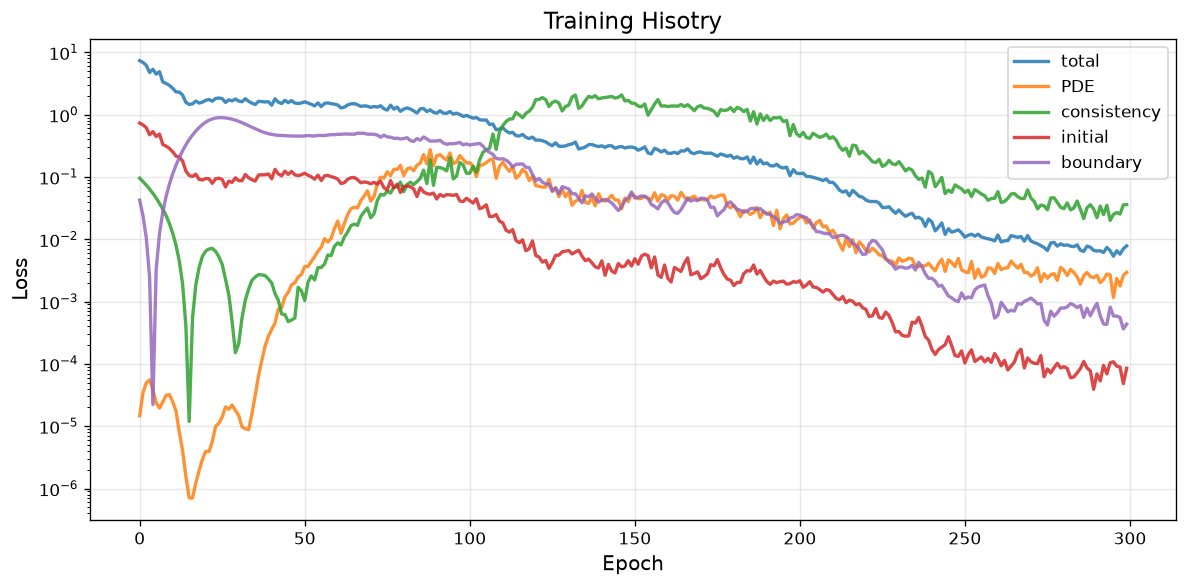

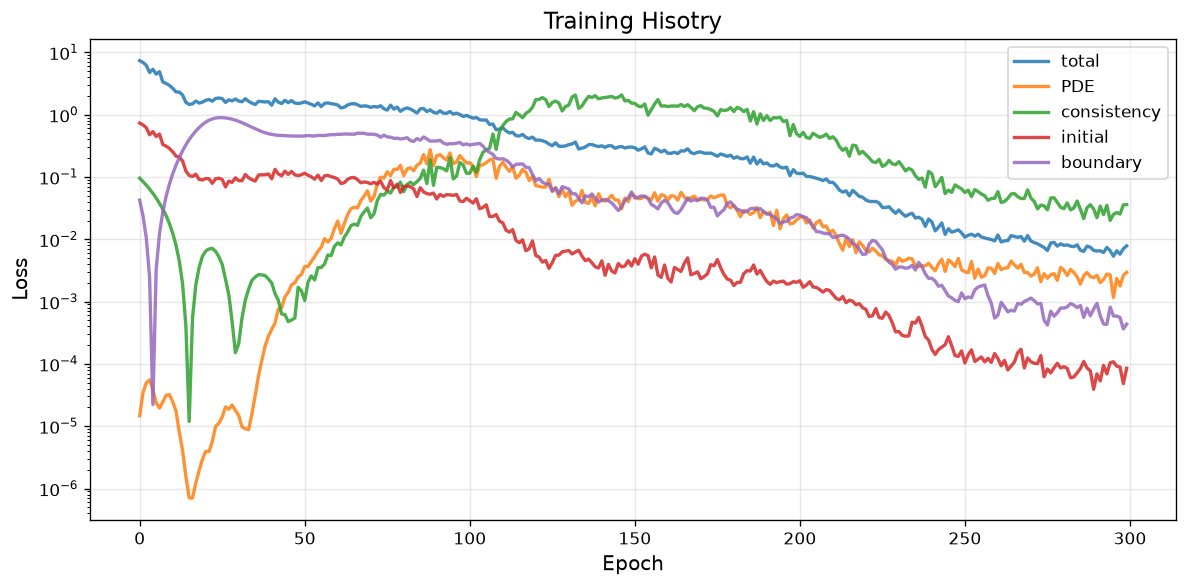

In [17]:
plot_training_history(
    history,
    save_path ='../figures/demo/history.png',  # set to None to skip saving
    show      = True,
)

## 7 - Evaluate model over grid

In [18]:
metrics, U_pred, U_true, x_grid, t_grid = evaluate(
    model  = model,
    pde    = used_pde
)
print(metrics)

Evaluating on 60×60 grid …
  Relative L2 : 1.6379e-02
  MAE         : 7.6148e-03
  Max abs err : 3.7116e-02
  RMSE        : 1.0205e-02
  Entropy     : 1.1181e+00
{'rel_l2': 0.01637878827750683, 'mae': 0.007614829111844301, 'max_abs_error': 0.03711627423763275, 'rmse': 0.010204963386058807, 'entropy': 1.1181014776229858, 'entropy_grid': tensor([[1.2426, 1.2423, 1.2421,  ..., 1.2099, 1.2091, 1.2082],
        [1.2413, 1.2411, 1.2409,  ..., 1.2073, 1.2064, 1.2055],
        [1.2380, 1.2378, 1.2376,  ..., 1.2032, 1.2022, 1.2013],
        ...,
        [1.1218, 1.1206, 1.1194,  ..., 1.0550, 1.0544, 1.0538],
        [1.1173, 1.1160, 1.1147,  ..., 1.0493, 1.0487, 1.0482],
        [1.1123, 1.1109, 1.1095,  ..., 1.0438, 1.0433, 1.0428]])}


## 8 - Plot solution comparison

Saved: ../figures/demo/solution_quant.png


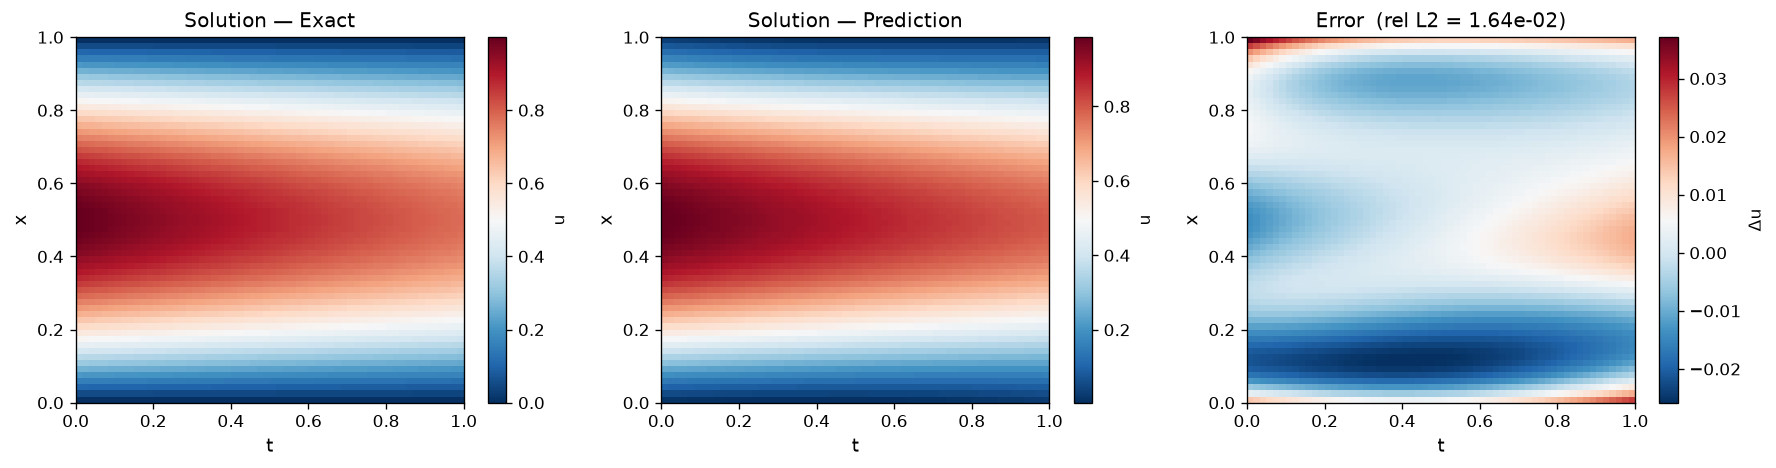

Relative L2 error: 1.6379e-02


In [19]:
fig, rel_l2 = plot_solution_comparison(
    U_pred    = U_pred,
    U_true    = U_true,
    x_grid    = x_grid,
    t_grid    = t_grid,
    save_path ='../figures/demo/solution_quant.png',
    show      = True,
)
print(f'Relative L2 error: {rel_l2:.4e}')

## 9 - Repeat process for Classial PINN to compare result

Parameters — total: 310  trainable: 310

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 1.0332e+01 | PDE: 3.56e-07 | Cons: 1.27e-03 | IC: 1.01e+00 | BC: 1.85e-01 | Time: 0.0s
Epoch    50/300 | Loss: 1.4294e+00 | PDE: 1.10e-01 | Cons: 1.07e-02 | IC: 9.91e-02 | BC: 3.28e-01 | Time: 0.1s
Epoch   100/300 | Loss: 9.8513e-01 | PDE: 6.98e-02 | Cons: 1.69e-01 | IC: 6.48e-02 | BC: 2.50e-01 | Time: 0.1s
Epoch   150/300 | Loss: 6.0511e-02 | PDE: 8.75e-03 | Cons: 2.69e-01 | IC: 1.38e-03 | BC: 1.11e-02 | Time: 0.2s
Epoch   200/300 | Loss: 2.9201e-02 | PDE: 2.27e-03 | Cons: 1.54e-01 | IC: 5.85e-04 | BC: 5.68e-03 | Time: 0.3s
Epoch   250/300 | Loss: 9.1783e-03 | PDE: 6.54e-04 | Cons: 6.58e-02 | IC: 6.60e-05 | BC: 1.28e-03 | Time: 0.3s
Epoch   300/300 | Loss: 8.7890e-03 | PDE: 1.01e-03 | Cons: 7.17e-02 | IC: 1.94e-05 | BC: 4.10e-04 | Time: 0.4s

Done — 0.4s total
Evaluating on 60×60 grid …
  Relative L2 : 1.9059e-02
  MAE         : 1.0275e-02
  Max abs err : 2.8619e-02
 

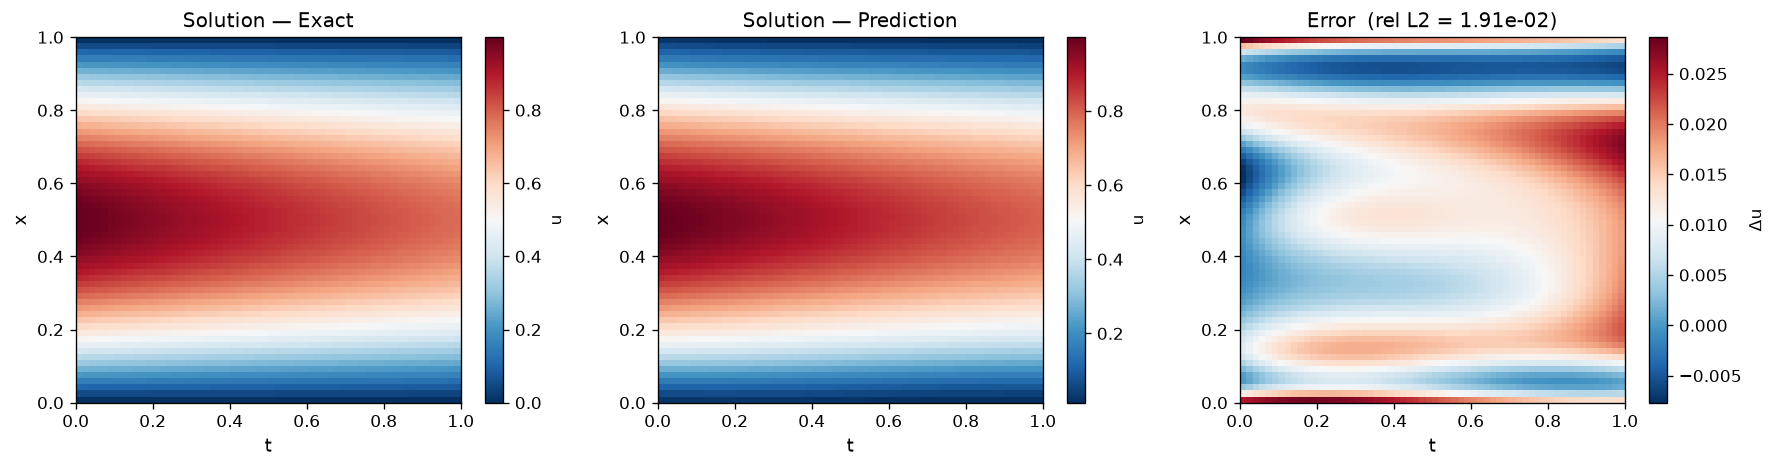

Relative L2 error: 1.9059e-02


In [9]:
from src.models import ClassicalHeatQPINN


classical_model = ClassicalHeatQPINN()
classical_model = classical_model.to(device)


history = train(model = classical_model, pde = used_pde, loss_fn=total_loss, epochs=300)

metrics, U_pred, U_true, x_grid, t_grid = evaluate(
    model  = classical_model,
    pde    = used_pde,
)

fig, rel_l2 = plot_solution_comparison(
    U_pred    = U_pred,
    U_true    = U_true,
    x_grid    = x_grid,
    t_grid    = t_grid,
    save_path ='../figures/demo/solution_class.png',
    show      = True,
)
print(f'Relative L2 error: {rel_l2:.4e}')